# 実験5 (ex005): EMNIST CompactCNN（非凸モデル）における FedSSO × MoQファミリー 10シード比較

論文 Table 1（下段右: EMNIST FOR CNN, $d = 6,230, n_c = 49,840\,\mathrm{B}$）に準拠した `CompactCNN` 上で全 11 手法を 10 シード比較します。
（※ 予備実験により Table 1 表記の $\alpha=0.003, \eta=1.0$ は全28万枚のEMNIST標準化データ上のCNNでは停滞したため、論文グリッドサーチ範囲内の最適値 $\alpha=0.03, \eta=0.3$ を全準ニュートン系へ統一適用しています）

In [1]:
import os
import torch
import pandas as pd
from model import verify_batched_cnn_equivalence
from utils import (
    DEFAULT_SEEDS, load_and_partition_emnist_2d, run_multiseed_emnist_cnn,
    plot_emnist_cnn_curves, plot_emnist_cnn_boxplot, plot_filtered_results,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'})")

使用デバイス: cuda (NVIDIA GeForce RTX 4080)


In [2]:
clients, packed_clients, X_train, y_train, X_test, y_test = load_and_partition_emnist_2d(
    data_dir="../datasets", num_clients=20, beta=0.1, train_ratio=0.75, seed=42, device=device
)
max_diff = verify_batched_cnn_equivalence(clients, packed_clients, tau=5, batch_size=100, lr=0.03, device=device)
print(f"EMNIST 2D train={X_train.shape}, test={X_test.shape} | 並列SGD最大誤差: {max_diff:.3e}")

EMNIST 2D train=torch.Size([209991, 1, 28, 28]), test=torch.Size([70009, 1, 28, 28]) | 並列SGD最大誤差: 2.980e-08


In [3]:
algo_configs = [
    {"name": "FedAvg",        "algo": "FedAvg",        "lr": 0.1},
    {"name": "FedSSO",        "algo": "FedSSO",        "lr": 0.03, "eta": 0.3},
    {"name": "FedSSO-NAQ",    "algo": "FedSSO-NAQ",    "lr": 0.03, "eta": 0.3, "mu": 0.25},
    {"name": "FedSSO-MoQ",    "algo": "FedSSO-MoQ",    "lr": 0.03, "eta": 0.3, "mu": 0.25},
    {"name": "FedSSO-AdaNAQ", "algo": "FedSSO-AdaNAQ", "lr": 0.03, "eta": 0.3, "max_mu": 0.30},
    {"name": "FedSSO-AdaMoQ", "algo": "FedSSO-AdaMoQ", "lr": 0.03, "eta": 0.3, "max_mu": 0.30},
    {"name": "FedSSO-LBFGS",  "algo": "FedSSO-LBFGS",  "lr": 0.03, "eta": 0.3, "m_size": 10},
    {"name": "FedSSO-LNAQ",   "algo": "FedSSO-LNAQ",   "lr": 0.03, "eta": 0.3, "max_mu": 0.30, "m_size": 10},
    {"name": "FedSSO-LMoQ",   "algo": "FedSSO-LMoQ",   "lr": 0.03, "eta": 0.3, "max_mu": 0.30, "m_size": 10},
    {"name": "FedSSO-MLNAQ",  "algo": "FedSSO-MLNAQ",  "lr": 0.03, "eta": 0.3, "max_mu": 0.30},
    {"name": "FedSSO-MLMoQ",  "algo": "FedSSO-MLMoQ",  "lr": 0.03, "eta": 0.3, "max_mu": 0.30},
]
summary_df, per_seed_df, curves_dict = run_multiseed_emnist_cnn(
    algo_configs=algo_configs, packed_clients=packed_clients,
    X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
    seeds=DEFAULT_SEEDS, rounds=200, tau=5, batch_size=100,
    targets=(0.60, 0.80, 0.90, 0.95, 0.97),
    save_log_dir="../datasets/ex005_emnist_cnn_logs",
    history_csv_path="../datasets/ex005_emnist_cnn_history.csv",
)
summary_df.to_csv("../datasets/ex005_emnist_cnn_summary.csv", index=False)
per_seed_df.to_csv("../datasets/ex005_emnist_cnn_per_seed.csv", index=False)
summary_df

,Algorithm,Comm_Per_Iter,Loss_Ave,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,MaxAcc_Ave,Clip_Ave,Reset_Ave,Server_Time_ms,Server_Mem_MB,Bytes@0.95,Reach@0.60,Iter@0.60,Comm@0.60,Reach@0.80,Iter@0.80,Comm@0.80,Reach@0.90,Iter@0.90,Comm@0.90,Reach@0.95,Iter@0.95,Comm@0.95,Reach@0.97,Iter@0.97,Comm@0.97
0,FedAvg,1.000,0.075980,0.975540,0.975489,0.978346,0.970804,0.002205,0.975655,0.0,0.0,0.009228,0.023766,3478832,10/10,7.5,7.5,10/10,13.6,13.6,10/10,29.8,29.8,10/10,69.8,69.8,10/10,142.3,142.3
1,FedSSO,1.000,0.041127,0.985915,0.987294,0.988616,0.978217,0.003058,0.986707,1.8,1.6,1.631240,148.154526,1829128,10/10,10.8,10.8,10/10,14.7,14.7,10/10,21.7,21.7,10/10,36.7,36.7,10/10,57.9,57.9
2,FedSSO-NAQ,1.995,0.519441,0.801528,0.983616,0.987187,0.097845,0.351213,0.828441,9.1,2.1,1.671287,148.202057,4448220,8/10,14.1,27.2,8/10,18.0,35.0,8/10,26.6,52.2,8/10,45.1,89.2,6/10,54.3,107.7
3,FedSSO-MoQ,1.000,0.051722,0.982714,0.983338,0.987159,0.975732,0.003327,0.983615,1.5,1.7,1.671231,148.225822,2591680,10/10,16.2,16.2,10/10,21.3,21.3,10/10,32.9,32.9,10/10,52.0,52.0,10/10,81.7,81.7
4,FedSSO-AdaNAQ,1.995,0.067595,0.977557,0.983038,0.987130,0.945950,0.012418,0.978324,1.7,2.2,1.677797,148.202057,5786978,10/10,14.1,27.2,10/10,21.4,41.8,10/10,36.2,71.4,9/10,58.6,116.1,8/10,72.9,144.8
5,FedSSO-AdaMoQ,1.000,0.070176,0.976882,0.982317,0.986745,0.946921,0.013467,0.977684,1.2,2.0,1.687243,148.225822,2918409,10/10,16.4,16.4,10/10,21.6,21.6,10/10,37.3,37.3,9/10,58.6,58.6,8/10,74.0,74.0
6,FedSSO-LBFGS,1.000,0.081299,0.973975,0.974296,0.976260,0.966861,0.002525,0.974498,14.3,1.5,1.640100,0.570374,3807776,10/10,16.1,16.1,10/10,21.1,21.1,10/10,36.8,36.8,10/10,76.4,76.4,9/10,145.6,145.6
7,FedSSO-LNAQ,1.995,0.309032,0.916088,0.969482,0.976274,0.677213,0.110148,0.973211,17.2,1.3,1.665678,0.617905,7785008,10/10,15.5,30.0,10/10,20.7,40.4,10/10,36.7,72.4,10/10,78.6,156.2,8/10,146.2,291.5
8,FedSSO-LMoQ,1.000,0.130070,0.958572,0.971247,0.975432,0.844420,0.038208,0.970704,14.2,1.7,1.626157,0.641670,4660040,10/10,16.9,16.9,10/10,24.3,24.3,10/10,44.9,44.9,10/10,93.5,93.5,8/10,158.9,158.9
9,FedSSO-MLNAQ,1.995,0.284448,0.910839,0.909397,0.940293,0.883458,0.019836,0.911963,148.1,1.1,0.812775,0.190125,19886160,10/10,22.6,44.2,10/10,28.6,56.2,7/10,70.0,139.0,0/10,NaN,NaN,0/10,NaN,NaN


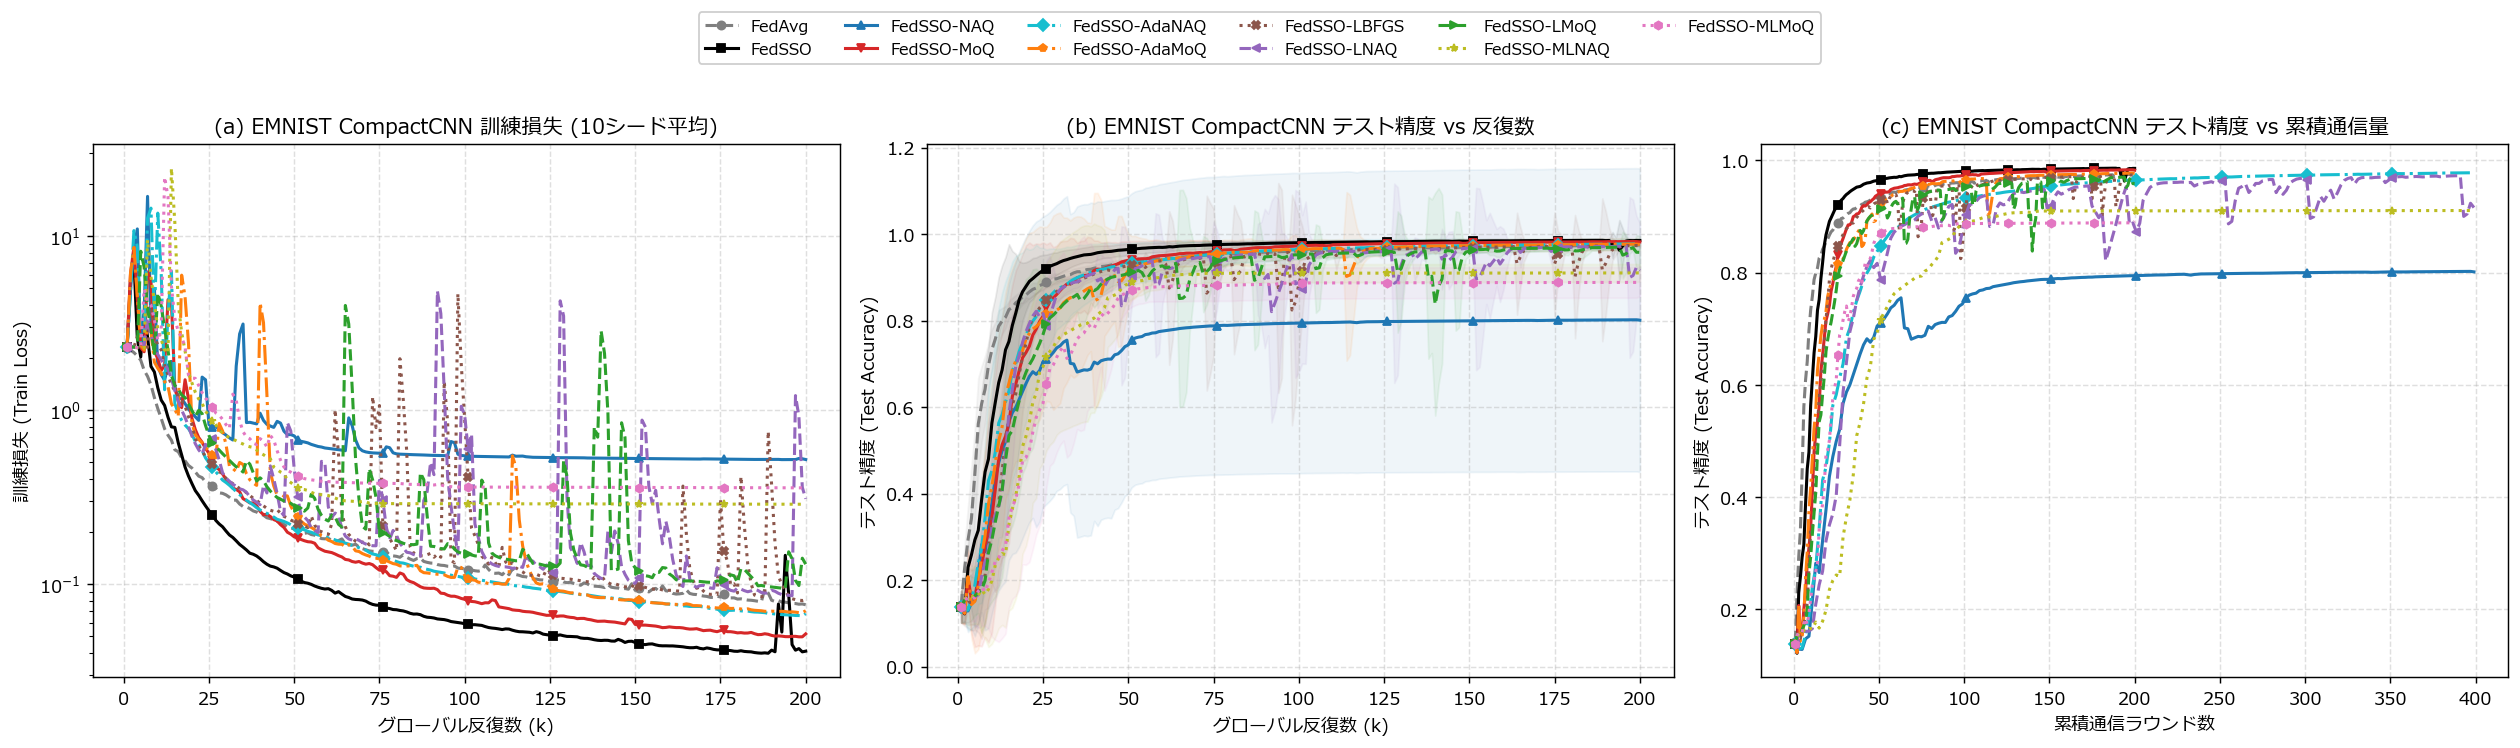

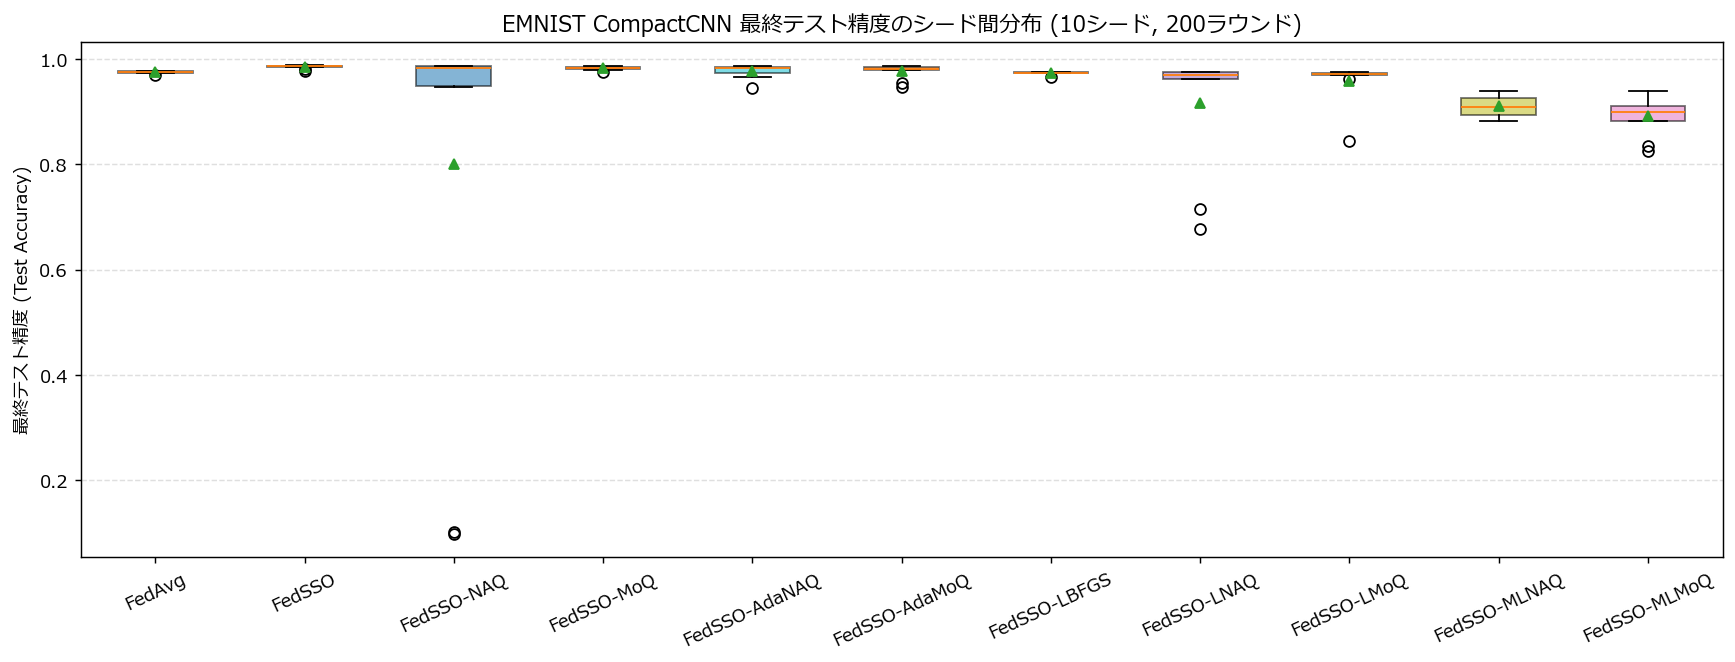

In [4]:
os.makedirs("../report/img", exist_ok=True)
plot_emnist_cnn_curves(curves_dict, save_path="../report/img/ex005_emnist_cnn_curves.png")
plot_emnist_cnn_boxplot(per_seed_df, save_path="../report/img/ex005_emnist_cnn_boxplot.png")

## 特定のシード値・アルゴリズムに絞ったグラフ表示

保存済みの全履歴 CSV（`../datasets/ex005_emnist_cnn_history.csv`）から任意のアルゴリズム・シード値だけを指定して再描画できます。 `SELECTED_SEEDS = None` のときは全シード平均のみを自動表示・出力します。

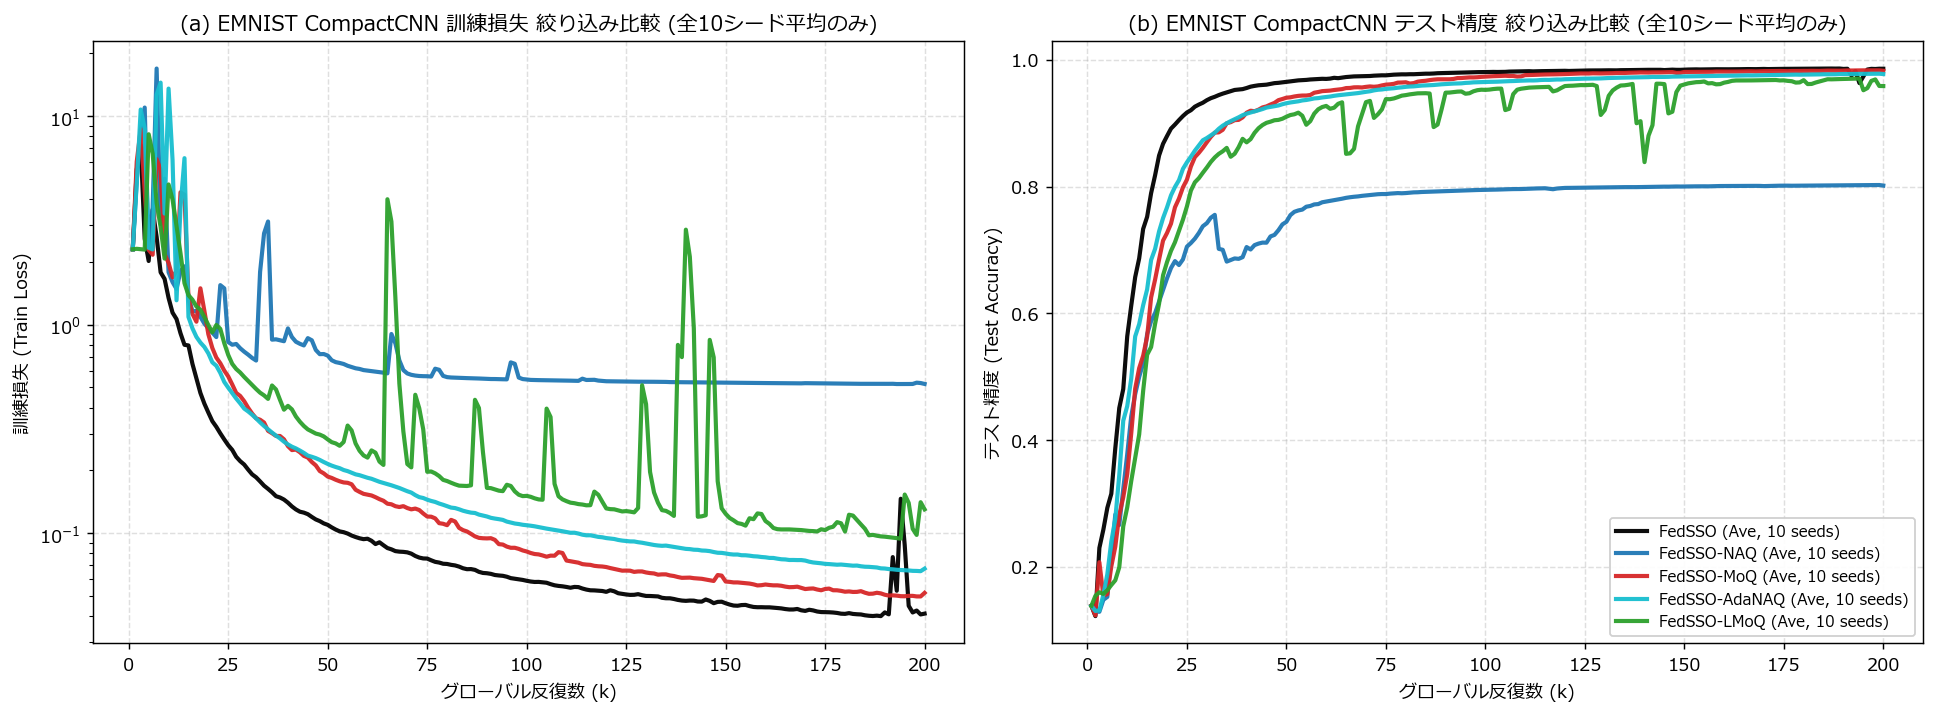

,Algorithm,Seeds,Round,Comm_Round,Train_Loss_Ave,Test_Acc_Ave
0,FedSSO,10,200,200.0,0.041127,0.985915
1,FedSSO-NAQ,10,200,399.0,0.519441,0.801528
2,FedSSO-MoQ,10,200,200.0,0.051722,0.982714
3,FedSSO-AdaNAQ,10,200,399.0,0.067595,0.977557
4,FedSSO-LMoQ,10,200,200.0,0.130070,0.958572


In [5]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示
# 利用可能なアルゴリズム:
#   ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-AdaMoQ",
#    "FedSSO-LBFGS", "FedSSO-LNAQ", "FedSSO-LMoQ", "FedSSO-MLNAQ", "FedSSO-MLMoQ"]
#   None を指定すると全手法が対象になります
# 利用可能なシード値: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] (None で全シード対象)
SELECTED_ALGOS = ["FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-LMoQ"]
SELECTED_SEEDS = None       # None で全10シード対象（例: [42, 46] で特定シードに絞り込み）
X_AXIS_MODE = "round"       # "round" (反復数) または "comm" (累積通信ラウンド数)
SHOW_MEAN_CURVE = True      # 複数シード指定時に平均太線を重ね描きするか
PLOT_MEAN_ONLY = "auto"     # "auto": SELECTED_SEEDS=None 時に平均線のみ描画 / True: 平均のみ / False: 個別シードも描画
TABLE_MEAN_ONLY = "auto"    # "auto": SELECTED_SEEDS=None 時に平均のみの行を出力 / True: 平均のみ / False: シード別に出力

filtered_df = plot_filtered_results(
    selected_algos=SELECTED_ALGOS,
    selected_seeds=SELECTED_SEEDS,
    history_csv_path="../datasets/ex005_emnist_cnn_history.csv",
    log_dir="../datasets/ex005_emnist_cnn_logs",
    x_axis=X_AXIS_MODE,
    show_mean=SHOW_MEAN_CURVE,
    plot_mean_only=PLOT_MEAN_ONLY,
    table_mean_only=TABLE_MEAN_ONLY,
)
filtered_df